<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Developer Survey Analysis | Understanding Data Distributions**
**IBM Skills Network guided lab | Portfolio edition**


### Project Overview
Charts are useful when they help answer a question, not simply because they make a dataset easier to look at. In this notebook, I examine how developer survey responses are distributed and compare patterns across experience and age groups.

**Guiding question:** What do the survey responses reveal about compensation, professional experience, working arrangements, and technology interests?

**Approach:** Connect to the survey database, extract relevant fields with SQL, prepare values for plotting, and interpret the resulting charts.

**Tools:** SQLite, SQL, Python, Pandas, and Matplotlib.

*This is an IBM Skills Network guided exercise. The original code, outputs, and attribution are retained; the additional explanations document the analysis for portfolio readers.*

Estimated time needed: **45** minutes


### Objectives

In this lab, you will perform the following:
- Visualize the distribution of data using histograms.
- Visualize relationships between features.
- Explore data composition and comparisons.

### Demo: Working with database


#### Download the database file.

In [1]:
!wget -O survey-data.sqlite https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite

--2026-10-14 21:25:39--  https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite
Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 
169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 
200 OK
Length: 211415040 (202M) [application/octet-stream]
Saving to: ‘survey-data.sqlite’

survey-data.sqlite    0%[                    ]       0  --.-KB/s               
survey-data.sqlite    3%[                    ]   7.16M  35.5MB/s               
survey-data.sqlite    5%[>                   ]  11.27M  26.7MB/s               
survey-data.sqlite    8%[>                   ]  17.73M  28.5MB/s               
survey-data.sqlite    9%[>                   ]  20.13M  20.4MB/s               
survey

#### Install the required libraries and import them


In [2]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 82.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.7 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━ 8.1/16.7 MB 42.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━ 10.2/16.7 MB 26.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━ 11.5/16.7 MB 20.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 20.3 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━

In [3]:
!pip install matplotlib
!pip install seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/9.9 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 103.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/5.4 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 154.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 84.0 MB/s eta 0:00:00

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/6.9 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 155.3 MB/s eta 0:00:00

   ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [pillow]
   ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [pillow]
   ━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [pillow]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━━━━ 3/7 [fonttools]
   ━━━━━━

In [4]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Connect to the SQLite database


In [5]:
conn = sqlite3.connect('survey-data.sqlite')

### Demo: Basic SQL queries

**Demo 1: Count the number of rows in the table**<br>
Before building charts, I confirm that the database connection works and inspect its contents. 

In [6]:
QUERY = "SELECT COUNT(*) FROM main"
df = pd.read_sql_query(QUERY, conn)
print(df)

   COUNT(*)
0     65437

The saved SQL result reports 65,437 records in the main table. The age-group summary shows that respondents aged 25-34 form the largest listed group, with 23,911 responses.

These figures describe the survey sample; they should not be assumed to represent the age distribution of all developers.

**Demo 2: List all tables**


In [7]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)

,Table_Name
0,main


**Demo 3: Group data by age**


In [8]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)

                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568

### Hands-on Lab: Visualizing Data with Histograms


#### 1. Visualizing the distribution of data (Histograms)


**1.1 Histogram of `CompTotal` (Total Compensation)**


Objective: Plot a histogram of `CompTotal` to visualize the distribution of respondents' total compensation.


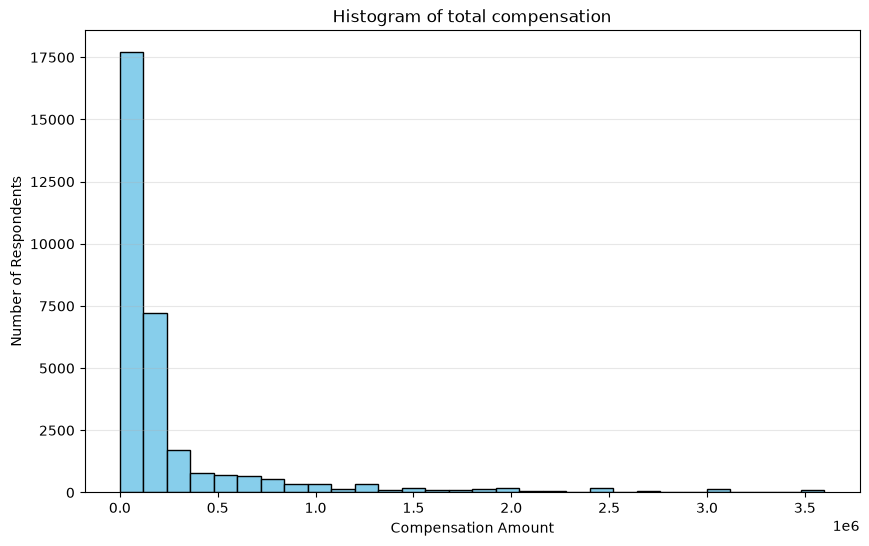

In [11]:
## Write your code here
QUERY = "SELECT CompTotal FROM main WHERE CompTotal IS NOT NULL"
df_comp = pd.read_sql_query(QUERY, conn)

upper_limit = df_comp['CompTotal'].quantile(0.95)
df_comp_filtered = df_comp[df_comp['CompTotal'] <= upper_limit]

plt.figure(figsize=(10, 6))
plt.hist(df_comp_filtered['CompTotal'], bins=30, color='skyblue', edgecolor='black')
plt.title('Histogram of total compensation')
plt.xlabel('Compensation Amount')
plt.ylabel('Number of Respondents')
plt.grid(axis='y', alpha=0.3)
plt.show()

Interpretation: The resulting histogram describes the filtered sample, not the full range of reported compensation. CompTotal may also contain amounts reported in different currencies, so the values should not be treated as directly comparable salaries without further standardization.

**1.2 Histogram of YearsCodePro (Years of Professional Coding Experience)**


Objective: Plot a histogram of `YearsCodePro` to analyze the distribution of coding experience among respondents.


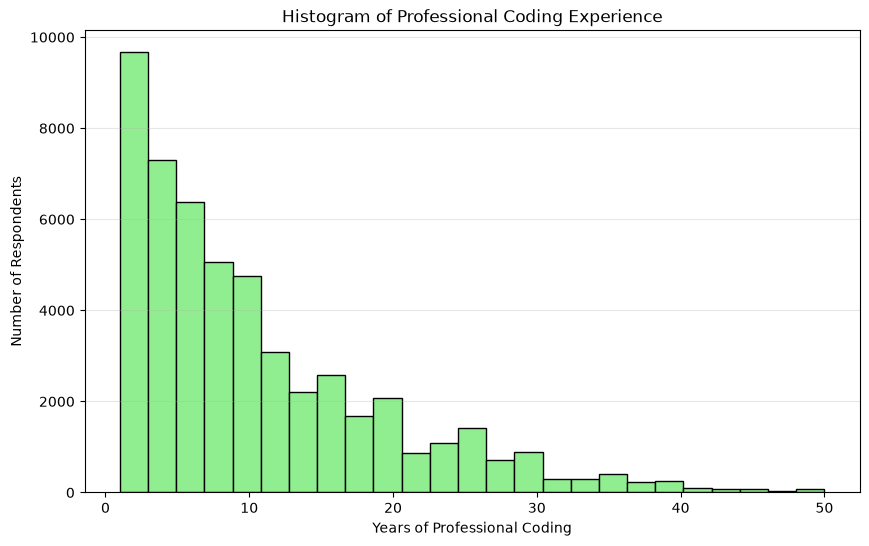

In [15]:
## Write your code here
QUERY = "SELECT YearsCodePro FROM main WHERE YearsCodePro IS NOT NULL"
df_years = pd.read_sql_query(QUERY, conn)

df_years['YearsCodePro_clean'] = df_years['YearsCodePro'].astype(str).str.extract(r'(\d+)').astype(float)
df_years = df_years.dropna(subset=['YearsCodePro_clean'])

plt.figure(figsize=(10, 6))
plt.hist(df_years['YearsCodePro_clean'], bins=25, color='lightgreen', edgecolor='black')
plt.title('Histogram of Professional Coding Experience')
plt.xlabel('Years of Professional Coding')
plt.ylabel('Number of Respondents')
plt.grid(axis='y', alpha=0.3)
plt.show()

This chart helps identify which experience ranges appear more frequently. It is important to note that extracting digits is an approximation: text responses such as Less than 1 year may not be represented accurately, and missing responses are excluded.

#### 2. Visualizing Relationships in Data


**2.1 Histogram Comparison of `CompTotal` by `Age` Group**


Objective: Use histograms to compare the distribution of CompTotal across different Age groups.


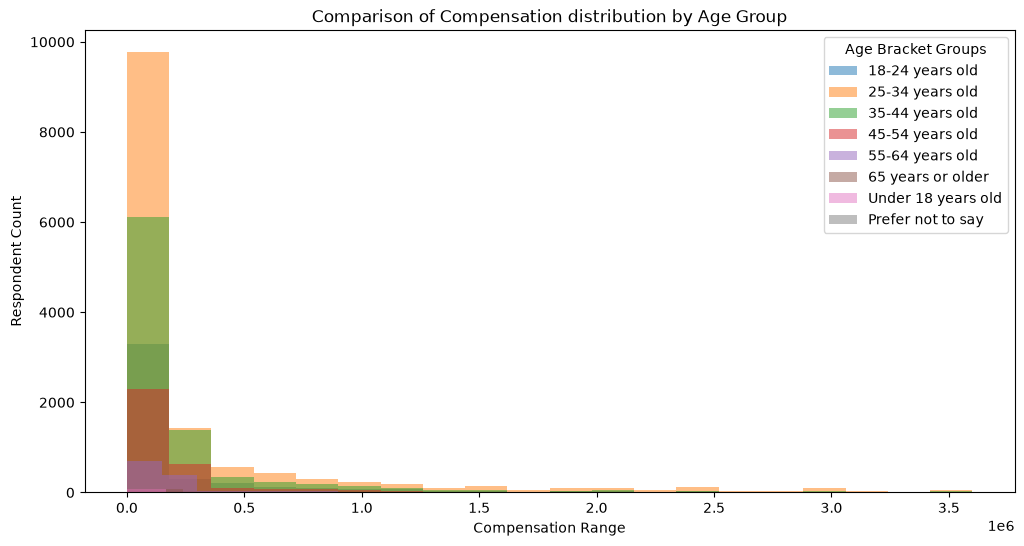

In [16]:
## Write your code here
QUERY = "SELECT Age, CompTotal FROM main WHERE Age IS NOT NULL AND CompTotal IS NOT NULL"
df_age_comp = pd.read_sql_query(QUERY, conn)

upper_limit = df_age_comp['CompTotal'].quantile(0.95)
age_comp_filtered = df_age_comp[df_age_comp['CompTotal'] <= upper_limit]
age_groups = age_comp_filtered['Age'].unique()

plt.figure(figsize=(12, 6))
for group in age_groups:
    subset = age_comp_filtered[age_comp_filtered['Age'] == group]
    plt.hist(subset['CompTotal'], bins=20, alpha=0.5, label=str(group))
plt.title('Comparison of Compensation distribution by Age Group')
plt.xlabel('Compensation Range')
plt.ylabel('Respondent Count')
plt.legend(title='Age Bracket Groups')
plt.show()

The code again excludes the top 5% of non-missing compensation values. Overlapping bars allow a broad visual comparison, although categories with more respondents will naturally produce taller bars. A comparison using percentages or density, along with a consistent currency, would be more suitable for assessing differences between groups.

**2.2 Histogram of TimeSearching for Different Age Groups**


Objective: Use histograms to explore the distribution of `TimeSearching` (time spent searching for information) for respondents across different age groups.


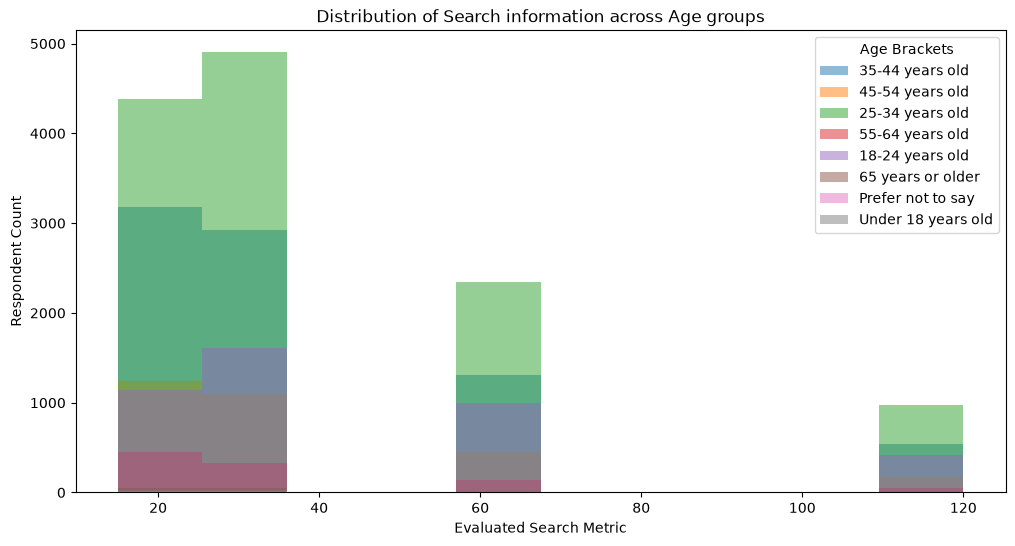

In [17]:
## Write your code here
QUERY = "SELECT Age, TimeSearching FROM main WHERE Age IS NOT NULL AND TimeSearching IS NOT NULL"
df_search = pd.read_sql_query(QUERY, conn)

df_search['TimeSearching_clean'] = df_search['TimeSearching'].astype(str).str.extract(r'(\d+)').astype(float)
df_search = df_search.dropna(subset=['TimeSearching_clean'])


age_groups = df_search['Age'].unique()
plt.figure(figsize=(12, 6))
for group in age_groups:
    subset = df_search[df_search['Age'] == group]
    plt.hist(subset['TimeSearching_clean'], bins=10, alpha=0.5, label=str(group))

plt.title('Distribution of Search information across Age groups')
plt.xlabel('Evaluated Search Metric')
plt.ylabel('Respondent Count')
plt.legend(title='Age Brackets')
plt.show()

The code extracts the first number from each response and plots overlapping histograms for different age groups.

**Interpretation caution:** The source answers are categories rather than precise measurements. Extracting the first number does not reliably convert a range or descriptive category into an exact amount of time. The chart is therefore best viewed as a demonstration of the plotting method, not a precise estimate of time spent searching.

### 3. Visualizing the Composition of Data


**3.1 Histogram of Most Desired Databases (`DatabaseWantToWorkWith`)**


Objective: Visualize the most desired databases for future learning using a histogram of the top 5 databases.<br>
Respondents can select more than one database in DatabaseWantToWorkWith. To count each choice, I split the semicolon-separated answers, place each selected database on its own row, and identify the five most frequently mentioned.


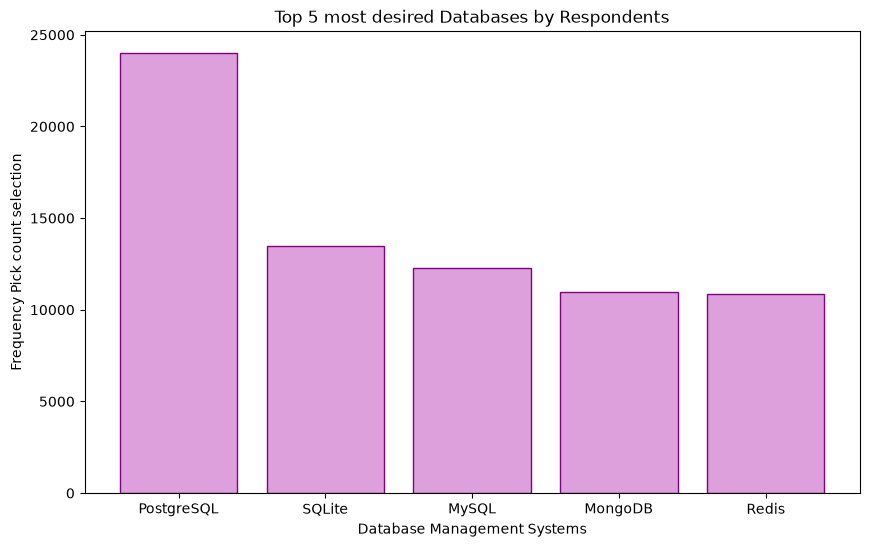

In [20]:
## Write your code here
QUERY = "SELECT DatabaseWantToWorkWith FROM main WHERE DatabaseWantToWorkWith IS NOT NULL"
db = pd.read_sql_query(QUERY, conn)

split_series = db['DatabaseWantToWorkWith'].str.split(';').explode()
top_dbs = split_series.value_counts().head(5)

plt.figure(figsize=(10, 6))
plt.bar(top_dbs.index, top_dbs.values, color='plum', edgecolor='purple')
plt.title('Top 5 most desired Databases by Respondents')
plt.xlabel('Database Management Systems')
plt.ylabel('Frequency Pick count selection')
plt.show()

**3.2 Histogram of Preferred Work Locations (`RemoteWork`)**


Objective: Use a histogram to explore the distribution of preferred work arrangements (`remote work`).<br>
The `RemoteWork` field groups respondents by their reported working arrangement. Counting these categories provides a straightforward view of the survey's remote, hybrid, and in-person responses.


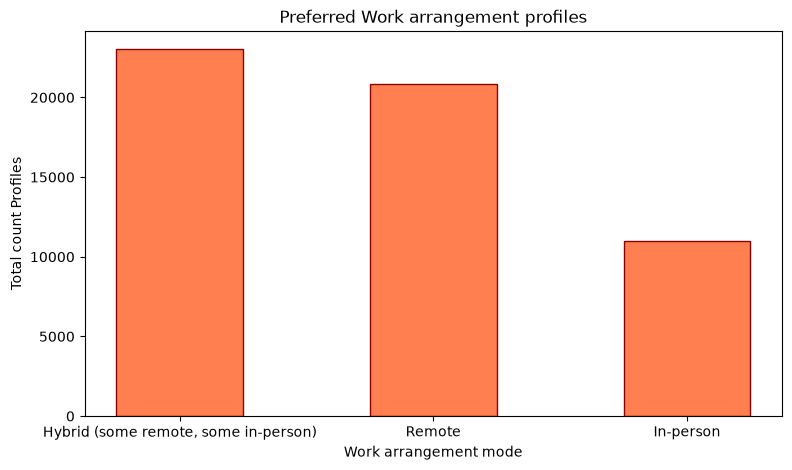

In [21]:
## Write your code here
QUERY = "SELECT RemoteWork FROM main WHERE RemoteWork IS NOT NULL"
df_remote = pd.read_sql_query(QUERY, conn)
work_arrangements = df_remote['RemoteWork'].value_counts()

plt.figure(figsize=(9, 5))
plt.bar(work_arrangements.index, work_arrangements.values, color='coral', edgecolor='darkred', width=0.5)
plt.title('Preferred Work arrangement profiles')
plt.xlabel('Work arrangement mode')
plt.ylabel('Total count Profiles')
plt.show()

### 4. Visualizing Comparison of Data


**4.1 Histogram of Median CompTotal for Ages 45 to 60**


Objective: Plot the histogram for `CompTotal` within the age group 45 to 60 to analyze compensation distribution among mid-career respondents.


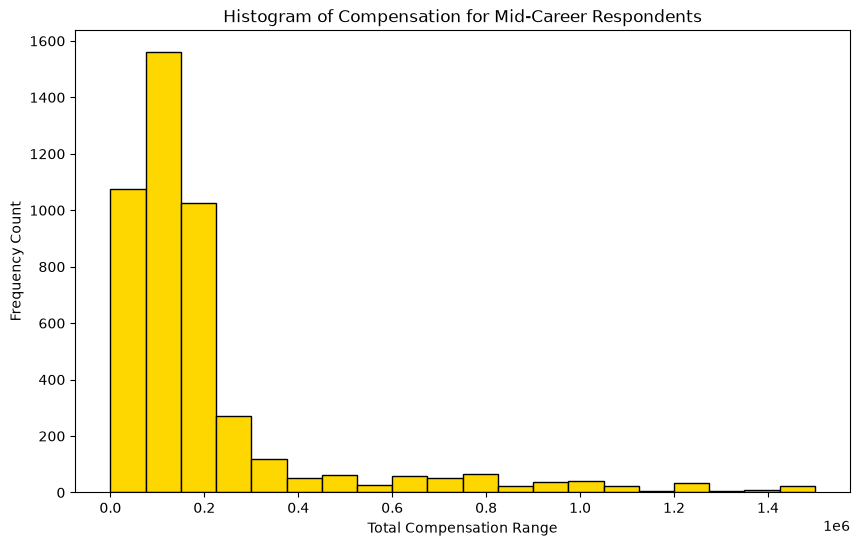

In [22]:
## Write your code here
QUERY = "SELECT Age, CompTotal FROM main WHERE Age IS NOT NULL AND CompTotal IS NOT NULL"
df_mid = pd.read_sql_query(QUERY, conn)

df_mid['Age_clean'] = df_mid['Age'].astype(str).str.extract(r'(\d+)').astype(float)
df_mid['CompTotal'] = pd.to_numeric(df_mid['CompTotal'], errors='coerce')
df_mid = df_mid.dropna(subset=['Age_clean', 'CompTotal'])

df_mid_filter = df_mid[(df_mid['Age_clean'] >= 45) & (df_mid['Age_clean'] <= 60)]
upper_limit = df_mid_filter['CompTotal'].quantile(0.95)
df_mid_final = df_mid_filter[df_mid_filter['CompTotal'] <= upper_limit]

plt.figure(figsize=(10, 6))
plt.hist(df_mid_final['CompTotal'], bins=20, color='gold', edgecolor='black')
plt.title('Histogram of Compensation for Mid-Career Respondents')
plt.xlabel('Total Compensation Range')
plt.ylabel('Frequency Count')
plt.show()

**Important limitation:**The survey records age ranges, not exact ages. For example, extracting 45 from 45-54 years old represents the start of that range. The filter may therefore include an entire age band and cannot precisely isolate respondents aged 45 through 60. Currency differences and percentile filtering also limit salary comparisons.

**4.2 Histogram of Job Satisfaction (`JobSat`) by YearsCodePro**


Objective: Plot the histogram for `JobSat` scores based on respondents' years of professional coding experience.


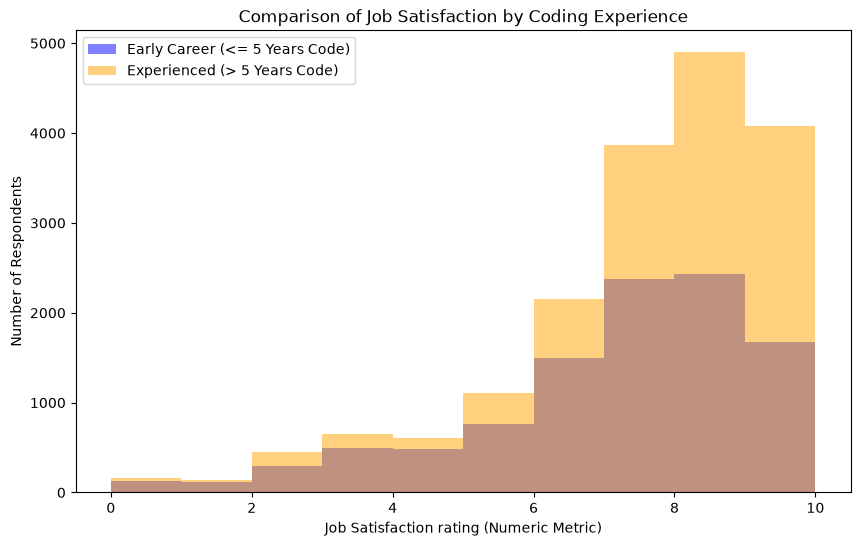

In [24]:
## Write your code here
QUERY = "SELECT JobSat, YearsCodePro FROM main WHERE JobSat IS NOT NULL AND YearsCodePro IS NOT NULL"
df_sat = pd.read_sql_query(QUERY, conn)


df_sat['JobSat_clean'] = pd.to_numeric(df_sat['JobSat'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
df_sat['Years_clean'] = pd.to_numeric(df_sat['YearsCodePro'].astype(str).str.extract(r'(\d+)')[0], errors='coerce')
df_sat = df_sat.dropna(subset=['JobSat_clean', 'Years_clean'])

short_exp = df_sat[df_sat['Years_clean'] <= 5]['JobSat_clean']
long_exp = df_sat[df_sat['Years_clean'] > 5]['JobSat_clean']


plt.figure(figsize=(10, 6))
plt.hist(short_exp, bins=10, alpha=0.5, label='Early Career (<= 5 Years Code)', color='blue')
plt.hist(long_exp, bins=10, alpha=0.5, label='Experienced (> 5 Years Code)', color='orange')
plt.title('Comparison of Job Satisfaction by Coding Experience')
plt.xlabel('Job Satisfaction rating (Numeric Metric)')
plt.ylabel('Number of Respondents')
plt.legend(loc='upper left')
plt.show()

Taller bars can reflect different group sizes, not necessarily higher satisfaction. To compare the groups more fairly, I would examine normalized distributions and summary statistics alongside these charts. The plot alone does not establish that experience causes satisfaction to change

### Final step: Close the database connection


Once you've completed the lab, make sure to close the connection to the SQLite database:



In [26]:
conn.close()

### Key Findings and Interpretation
- The database contains 65,437 survey records, providing a substantial sample for exploratory visualization.
- The age-group summary identifies 25-34 years as the largest listed category, with 23,911 responses.
- Compensation histograms help reveal the shape of the reported values, but excluding the highest 5% and mixing possible currencies mean these are not reliable salary benchmarks.
- Experience, working arrangement, and database-interest charts describe how responses are distributed within the survey; they do not establish workforce-wide trends or preferences.
- Comparing categories with raw histogram counts can be misleading when the groups contain different numbers of respondents.

### Limitations and Next Steps
The dataset is self-reported, some questions allow multiple selections, and some numerical fields are derived from categorical text. These details affect how confidently the charts can be interpreted. In a follow-up analysis, I would standardize compensation currencies, preserve age and time-searching ranges as categories, and use percentages or normalized distributions for comparisons between groups.

### Skills Demonstrated
- SQL and database access: Connecting to SQLite and querying survey fields.
- Data preparation: Filtering missing values, extracting values, and splitting multi-select responses.
- Visualization: Creating and interpreting histograms and categorical bar charts.
- Analytical communication: Explaining what the charts show and where the evidence is limited.

### Summary


In this lab, you used histograms to visualize various aspects of the dataset, focusing on:
- Distribution of compensation, coding experience, and work hours.
- Relationships in compensation across age groups and work status.
- Composition of data by desired databases and work environments.
- Comparisons of job satisfaction across years of experience.

Histograms helped reveal patterns and distributions in the data, enhancing your understanding of developer demographics and preferences.

*Original lab material, branding, and attribution: IBM Skills Network. Portfolio explanations have been added.*

## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
